# Dataset and Assignment 1 summary

Because I had to change dataset in between assignment 1 and assignment 2, here is a summary of the new dataset information and code from the first assignment tasks, to explore the statistical aspects of the network.

The new network maps the rail connections between train stations in the UK (data available at https://github.com/andresantoro/Tranet_data/tree/master to be downloaded, originally scraped from http://www.opentraintimes.com/). Dataset was provided as multiple .txt files. Thus, the first steps of this notebook combine the different files and export them as a .csv. 

Nodes represent train stations, while edges represent whether there is a direct connection between the two stations. The graph is undirected, and simply indicates whether there is a service between two nodes (i.e. stations), and unweighted.

## Imports

In [10]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import seaborn as sns
from pathlib import Path
import re

%matplotlib inline
plt.style.use("default")
sns.set_palette("husl")

## Data Loading and Cleaning

In [ ]:
# ============================================================
# 1. FILE PATHS
# ============================================================
DATA_DIR = Path("Model-Based-Decisions-Code/Assignment 2/data")

COMPANIES_FILE = DATA_DIR / "rail_companies.txt"
NODES_FILE = DATA_DIR / "nodes_list.txt"

OUTPUT_FILE = DATA_DIR / "uk_train_network.csv"


# ============================================================
# 2. READ TRAIN COMPANIES
# ============================================================

companies = {}

with open(COMPANIES_FILE, "r", encoding="utf-8-sig") as f:
    for line in f:
        line = line.strip()

        if not line:
            continue

        code, name = line.split("|", 1)

        companies[len(companies) + 1] = {
            "code": code.strip(),
            "name": name.strip()
        }

print(f"Loaded {len(companies)} train companies.")


# ============================================================
# 3. READ STATION NODES
# ============================================================

with open(NODES_FILE, "r", encoding="utf-8-sig") as f:
    nodes = {
        line.strip()
        for line in f
        if line.strip()
    }

print(f"Loaded {len(nodes)} station names.")


# ============================================================
# 4. FIND ALL LAYER FILES
# ============================================================

# Matches both:
# layer1.txt_original
# layer37.txt

layer_files = []

for file in DATA_DIR.iterdir():

    match = re.fullmatch(
        r"layer(\d+)\.txt(?:_original)?",
        file.name
    )

    if match:
        layer_number = int(match.group(1))
        layer_files.append((layer_number, file))

# Sort numerically, not alphabetically
layer_files.sort(key=lambda x: x[0])

print(f"Found {len(layer_files)} layer files.")

if len(layer_files) != 41:
    print("WARNING: Expected 41 layer files!")


# ============================================================
# 5. EXTRACT ALL CONNECTIONS
# ============================================================

all_connections = []
invalid_rows = []
unknown_nodes = set()

for layer_number, file_path in layer_files:

    # Check whether a corresponding carrier exists
    if layer_number not in companies:
        print(f"WARNING: No company mapping for layer {layer_number}")
        continue

    carrier = companies[layer_number]

    print(
        f"Processing layer {layer_number}: "
        f"{carrier['name']}"
    )

    with open(file_path, "r", encoding="utf-8-sig") as f:

        for line_number, line in enumerate(f, start=1):

            line = line.strip()

            if not line:
                continue

            # Split connection into two stations
            parts = line.split("|")

            if len(parts) != 2:
                invalid_rows.append({
                    "file": file_path.name,
                    "line": line_number,
                    "content": line
                })
                continue

            source = parts[0].strip()
            target = parts[1].strip()

            # Check whether stations appear in nodes_list.txt
            if source not in nodes:
                unknown_nodes.add(source)

            if target not in nodes:
                unknown_nodes.add(target)

            # Add connection and carrier information
            all_connections.append({
                "source": source,
                "target": target,
                "carrier_code": carrier["code"],
                "carrier_name": carrier["name"],
                "layer": layer_number
            })


# ============================================================
# 6. CREATE DATAFRAME
# ============================================================

df = pd.DataFrame(all_connections)

# Preserve all connections, including duplicates
df = df[
    [
        "source",
        "target",
        "carrier_code",
        "carrier_name",
        "layer"
    ]
]


# ============================================================
# 7. EXPORT CSV
# ============================================================

df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")


# ============================================================
# 8. DATA QUALITY REPORT
# ============================================================

print("\n========== NETWORK SUMMARY ==========")

print(f"Total connections: {len(df)}")
print(f"Unique stations in connection data: "
      f"{len(set(df['source']) | set(df['target']))}")

print(f"Number of carriers: {df['carrier_code'].nunique()}")
print(f"Number of layers: {df['layer'].nunique()}")

print(f"Invalid rows: {len(invalid_rows)}")
print(f"Station names not in nodes_list.txt: "
      f"{len(unknown_nodes)}")

print("\nConnections per carrier:")
print(df.groupby(
    ["carrier_code", "carrier_name"]
).size().to_string())

print(f"\nCSV successfully saved to: {OUTPUT_FILE}")

# Optional: save data quality reports
if invalid_rows:
    pd.DataFrame(invalid_rows).to_csv(
        DATA_DIR / "invalid_rows.csv", index=False
    )

if unknown_nodes:
    pd.DataFrame(
        sorted(unknown_nodes),
        columns=["unknown_station"]
    ).to_csv(
        DATA_DIR / "unknown_stations.csv", index=False
    )


Loaded 41 train companies.
Loaded 2944 station names.
Found 41 layer files.
Processing layer 1: Alliance Rail
Processing layer 2: Arriva Trains Wales
Processing layer 3: C2C
Processing layer 4: Chiltern Railways
Processing layer 5: Caledonian Sleeper
Processing layer 6: East Midlands Trains
Processing layer 7: Eurostar
Processing layer 8: ************
Processing layer 9: Grand Central
Processing layer 10: Great Northern Railway
Processing layer 11: Virgin Train East Coast
Processing layer 12: Great West Railway
Processing layer 13: Gatwick Express
Processing layer 14: Heathrow Connect
Processing layer 15: Hull Trains
Processing layer 16: Heathrow Express
Processing layer 17: Island Line
Processing layer 18: Greater Anglia
Processing layer 19: London Midland
Processing layer 20: London Overground
Processing layer 21: Network Rail (On-Track Machines)
Processing layer 22: Locomotive Services
Processing layer 23: LUL District Line (Wimbledon, Richmond), Bakerloo
Processing layer 24: Mersey

## Loading the new dataset

In [8]:
# File path: the CSV produced by the data-consolidation script
data_file = "Model-Based-Decisions-Code/Assignment 2/data/uk_train_network.csv"

df = pd.read_csv(data_file)

required_columns = {"source", "target", "carrier_code", "carrier_name", "layer"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {missing_columns}")

print(f"Loaded {len(df):,} connection records")
print(f"Data shape: {df.shape}")

# Remove rows with missing endpoints or carrier identifiers
df = df.dropna(subset=["source", "target", "carrier_code"]).copy()

# Normalize whitespace in station names and carrier codes
for col in ["source", "target", "carrier_code", "carrier_name"]:
    df[col] = df[col].astype("string").str.strip()

# Remove empty endpoints
df = df[(df["source"] != "") & (df["target"] != "")].copy()

print(f"Records after cleaning: {len(df):,}")
print("\nFirst five rows:")
display(df.head())

Loaded 8,996 connection records
Data shape: (8996, 5)
Records after cleaning: 8,996

First five rows:


,source,target,carrier_code,carrier_name,layer
0,Southampton Central,Eastleigh T.&R.S.M.D,AR,Alliance Rail,1
1,Birmingham International,Chester,AW,Arriva Trains Wales,2
2,Chester,Wolverhampton,AW,Arriva Trains Wales,2
3,Cardiff Central Bus Station,Cardiff International APT,AW,Arriva Trains Wales,2
4,Cardiff Central,Canton C.S.D.,AW,Arriva Trains Wales,2


## Constructing the network

In [11]:
def create_railway_network(data):
    """Create an undirected aggregate railway graph from carrier-level records."""
    G = nx.Graph()

    # Use a canonical ordering for undirected station pairs
    edge_data = {}

    for row in data.itertuples(index=False):
        source = str(row.source).strip()
        target = str(row.target).strip()

        # Match the previous assignment: exclude self-loops
        if not source or not target or source == target:
            continue

        u, v = sorted((source, target))
        key = (u, v)

        if key not in edge_data:
            edge_data[key] = {"carriers": set(), "carrier_names": set()}

        edge_data[key]["carriers"].add(str(row.carrier_code))
        if pd.notna(row.carrier_name):
            edge_data[key]["carrier_names"].add(str(row.carrier_name))

    for (u, v), info in edge_data.items():
        G.add_edge(
            u,
            v,
            weight=len(info["carriers"]),
            carriers=sorted(info["carriers"]),
            carrier_names=sorted(info["carrier_names"])
        )

    print(
        f"Network created with {G.number_of_nodes():,} stations "
        f"and {G.number_of_edges():,} unique station-pair connections."
    )
    return G


G = create_railway_network(df)

Network created with 2,941 stations and 8,572 unique station-pair connections.


## Statistical Analysis

In [12]:
def network_summary(G, data):
    """Print descriptive statistics for the aggregate railway network."""
    if G.number_of_nodes() == 0:
        raise ValueError("The graph is empty. Check the input CSV.")

    N = G.number_of_nodes()
    M = G.number_of_edges()
    components = list(nx.connected_components(G))
    largest_cc = max(components, key=len)
    G_lcc = G.subgraph(largest_cc).copy()

    degrees = [degree for _, degree in G.degree()]
    strengths = [strength for _, strength in G.degree(weight="weight")]

    print("=" * 65)
    print("UK RAILWAY NETWORK SUMMARY")
    print("=" * 65)
    print(f"Connection records in CSV: {len(data):,}")
    print(f"Stations (nodes): {N:,}")
    print(f"Unique station-pair connections (edges): {M:,}")
    print(f"Carriers represented: {data['carrier_code'].nunique():,}")
    print(f"Connected components: {len(components):,}")
    print(f"Largest connected component: {G_lcc.number_of_nodes():,} stations")
    print(f"LCC proportion: {G_lcc.number_of_nodes() / N * 100:.2f}%")
    print(f"Network density: {nx.density(G):.8f}")
    print(f"Average degree: {np.mean(degrees):.4f}")
    print(f"Average weighted degree (carrier strength): {np.mean(strengths):.4f}")
    print(f"Average clustering: {nx.average_clustering(G):.4f}")
    print(f"Global transitivity: {nx.transitivity(G):.4f}")

    assortativity = nx.degree_assortativity_coefficient(G)
    print(f"Degree assortativity: {assortativity:.4f}")

    # Path statistics are calculated on the largest connected component,
    # as in the previous assignment.
    if G_lcc.number_of_nodes() > 1:
        print(
            "Average shortest path length (LCC): "
            f"{nx.average_shortest_path_length(G_lcc):.4f}"
        )
        print(f"Network diameter (LCC): {nx.diameter(G_lcc):,}")
    else:
        print("Path length and diameter: not defined for a one-node LCC")

    print("\nDegree statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Maximum degree: {max(degrees):,}")
    print(f"Minimum degree: {min(degrees):,}")
    print(f"Standard deviation: {np.std(degrees):.2f}")

    print("\nTop 10 stations by degree:")
    for station, degree in sorted(G.degree(), key=lambda x: x[1], reverse=True)[:10]:
        print(f"{station}: {degree}")

    print("\nTop 10 station pairs by number of carriers:")
    top_edges = sorted(
        G.edges(data=True),
        key=lambda x: x[2]["weight"],
        reverse=True
    )[:10]
    for u, v, attrs in top_edges:
        print(f"{u} — {v}: {attrs['weight']} carrier(s)")


network_summary(G, df)

UK RAILWAY NETWORK SUMMARY
Connection records in CSV: 8,996
Stations (nodes): 2,941
Unique station-pair connections (edges): 8,572
Carriers represented: 41
Connected components: 34
Largest connected component: 2,867 stations
LCC proportion: 97.48%
Network density: 0.00198276
Average degree: 5.8293
Average weighted degree (carrier strength): 6.1176
Average clustering: 0.2564
Global transitivity: 0.1724
Degree assortativity: -0.0271
Average shortest path length (LCC): 4.6761
Network diameter (LCC): 13

Degree statistics:
Mean degree: 5.83
Median degree: 3.00
Maximum degree: 89
Minimum degree: 1
Standard deviation: 9.15

Top 10 stations by degree:
Edinburgh: 89
Manchester Piccadilly: 84
Cardiff Central: 80
London Waterloo (Main): 78
Eastleigh East Yard: 75
Birmingham New Street: 74
Leeds: 74
London Victoria: 71
Hoo Junction Up Yard: 71
Glasgow Central High Level: 65

Top 10 station pairs by number of carriers:
Craigentinny T.& R.S.M.D — Edinburgh: 7 carrier(s)
Edinburgh — Dundee: 5 carrie

## Degree Distributions

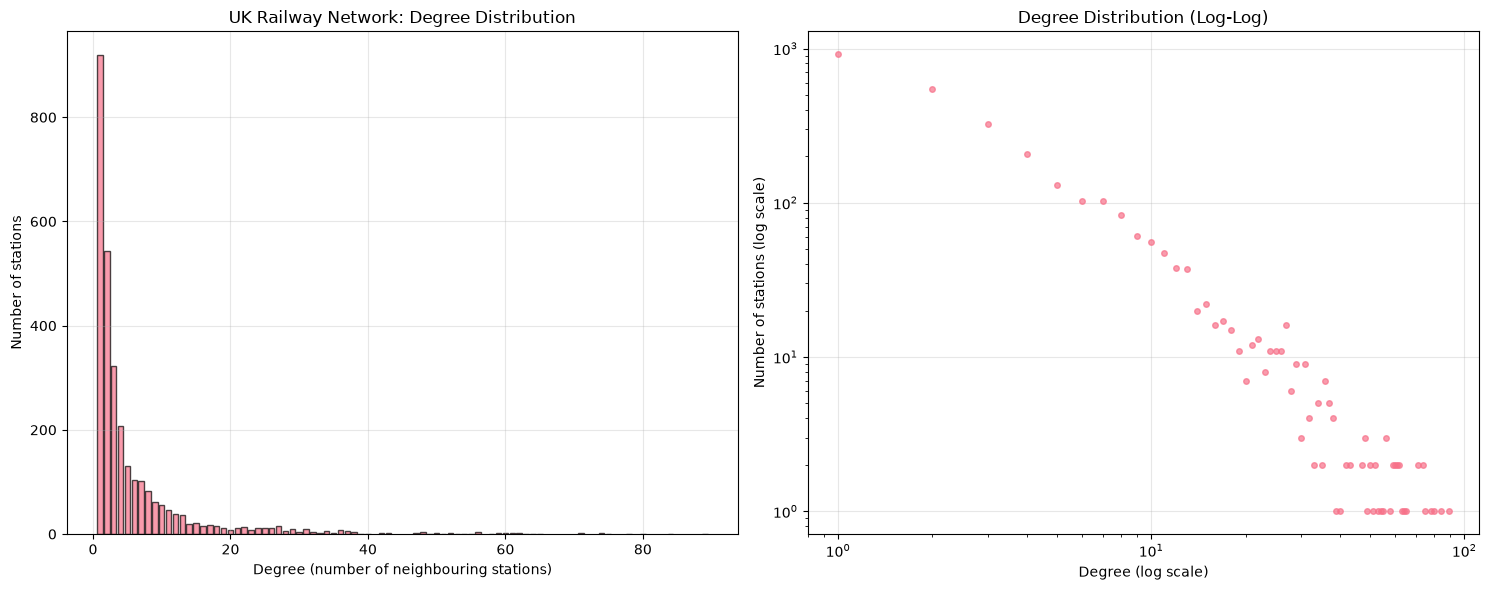


Degree distribution statistics:
Mean degree: 5.83
Median degree: 3.00
Maximum degree: 89
Minimum degree: 1
Standard deviation: 9.15


In [13]:
def plot_degree_distribution(G):
    """Plot degree distribution on linear and log-log scales."""
    degrees = [degree for _, degree in G.degree()]
    degree_counts = Counter(degrees)

    degree_values = sorted(degree_counts)
    counts = [degree_counts[d] for d in degree_values]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    ax1.bar(degree_values, counts, alpha=0.7, edgecolor="black")
    ax1.set_xlabel("Degree (number of neighbouring stations)")
    ax1.set_ylabel("Number of stations")
    ax1.set_title("UK Railway Network: Degree Distribution")
    ax1.grid(True, alpha=0.3)

    # Degree zero does not occur in a graph built only from observed edges;
    # filter non-positive values for logarithmic axes regardless.
    positive = [(d, c) for d, c in zip(degree_values, counts) if d > 0 and c > 0]
    if positive:
        x, y = zip(*positive)
        ax2.loglog(x, y, "o", alpha=0.7, markersize=4)
    ax2.set_xlabel("Degree (log scale)")
    ax2.set_ylabel("Number of stations (log scale)")
    ax2.set_title("Degree Distribution (Log-Log)")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("uk_rail_degree_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("\nDegree distribution statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Maximum degree: {max(degrees):,}")
    print(f"Minimum degree: {min(degrees):,}")
    print(f"Standard deviation: {np.std(degrees):.2f}")


plot_degree_distribution(G)

## Centrality Analysis

In [14]:
def calculate_centrality_measures(G):
    """Calculate degree, betweenness, closeness and eigenvector centrality."""
    if G.number_of_nodes() == 0:
        raise ValueError("Cannot calculate centrality on an empty graph.")

    centralities = {}

    print("Calculating degree centrality...")
    centralities["degree"] = nx.degree_centrality(G)

    print("Calculating betweenness centrality...")
    if G.number_of_nodes() > 1000:
        k = min(1000, G.number_of_nodes())
        centralities["betweenness"] = nx.betweenness_centrality(
            G, k=k, seed=42
        )
        print(f"Using approximation with k={k} sampled nodes.")
    else:
        centralities["betweenness"] = nx.betweenness_centrality(G)

    largest_cc = max(nx.connected_components(G), key=len)
    G_lcc = G.subgraph(largest_cc).copy()

    print("Calculating closeness centrality on the largest connected component...")
    closeness_lcc = nx.closeness_centrality(G_lcc)
    centralities["closeness"] = {
        node: closeness_lcc.get(node, 0.0) for node in G.nodes()
    }

    print("Calculating eigenvector centrality on the largest connected component...")
    try:
        eigenvector_lcc = nx.eigenvector_centrality(
            G_lcc, max_iter=1000, tol=1e-06
        )
    except nx.PowerIterationFailedConvergence:
        print("Eigenvector centrality did not converge; using NumPy solver.")
        eigenvector_lcc = nx.eigenvector_centrality_numpy(G_lcc)

    centralities["eigenvector"] = {
        node: eigenvector_lcc.get(node, 0.0) for node in G.nodes()
    }

    return centralities


centralities = calculate_centrality_measures(G)

Calculating degree centrality...
Calculating betweenness centrality...
Using approximation with k=1000 sampled nodes.
Calculating closeness centrality on the largest connected component...
Calculating eigenvector centrality on the largest connected component...


In [15]:
def display_top_stations(centralities, top_n=10):
    """Display the top stations for each centrality measure."""
    print("=" * 70)
    print(f"TOP {top_n} RAILWAY STATIONS BY CENTRALITY")
    print("=" * 70)

    for measure_name, values in centralities.items():
        print(f"\n{measure_name.upper()} CENTRALITY")
        print("-" * 50)

        ranked = sorted(values.items(), key=lambda item: item[1], reverse=True)
        for rank, (station, score) in enumerate(ranked[:top_n], start=1):
            print(f"{rank:2d}. {station}: {score:.6f}")


display_top_stations(centralities, top_n=10)

TOP 10 RAILWAY STATIONS BY CENTRALITY

DEGREE CENTRALITY
--------------------------------------------------
 1. Edinburgh: 0.030272
 2. Manchester Piccadilly: 0.028571
 3. Cardiff Central: 0.027211
 4. London Waterloo (Main): 0.026531
 5. Eastleigh East Yard: 0.025510
 6. Birmingham New Street: 0.025170
 7. Leeds: 0.025170
 8. London Victoria: 0.024150
 9. Hoo Junction Up Yard: 0.024150
10. Glasgow Central High Level: 0.022109

BETWEENNESS CENTRALITY
--------------------------------------------------
 1. Edinburgh: 0.080691
 2. Wembley Eur Frt Ops Cntre: 0.073670
 3. Derby R.T.C. (Network Rail): 0.060486
 4. Eastleigh East Yard: 0.055816
 5. Basford Hall S.S.M.: 0.050638
 6. Hoo Junction Up Yard: 0.047291
 7. Belmont Down Yard: 0.041955
 8. London Euston: 0.040427
 9. Toton North Yard: 0.039392
10. Reading: 0.038651

CLOSENESS CENTRALITY
--------------------------------------------------
 1. Wembley Eur Frt Ops Cntre: 0.324318
 2. Edinburgh: 0.321553
 3. Derby R.T.C. (Network Rail): 0.

## Visual comparison of centralities

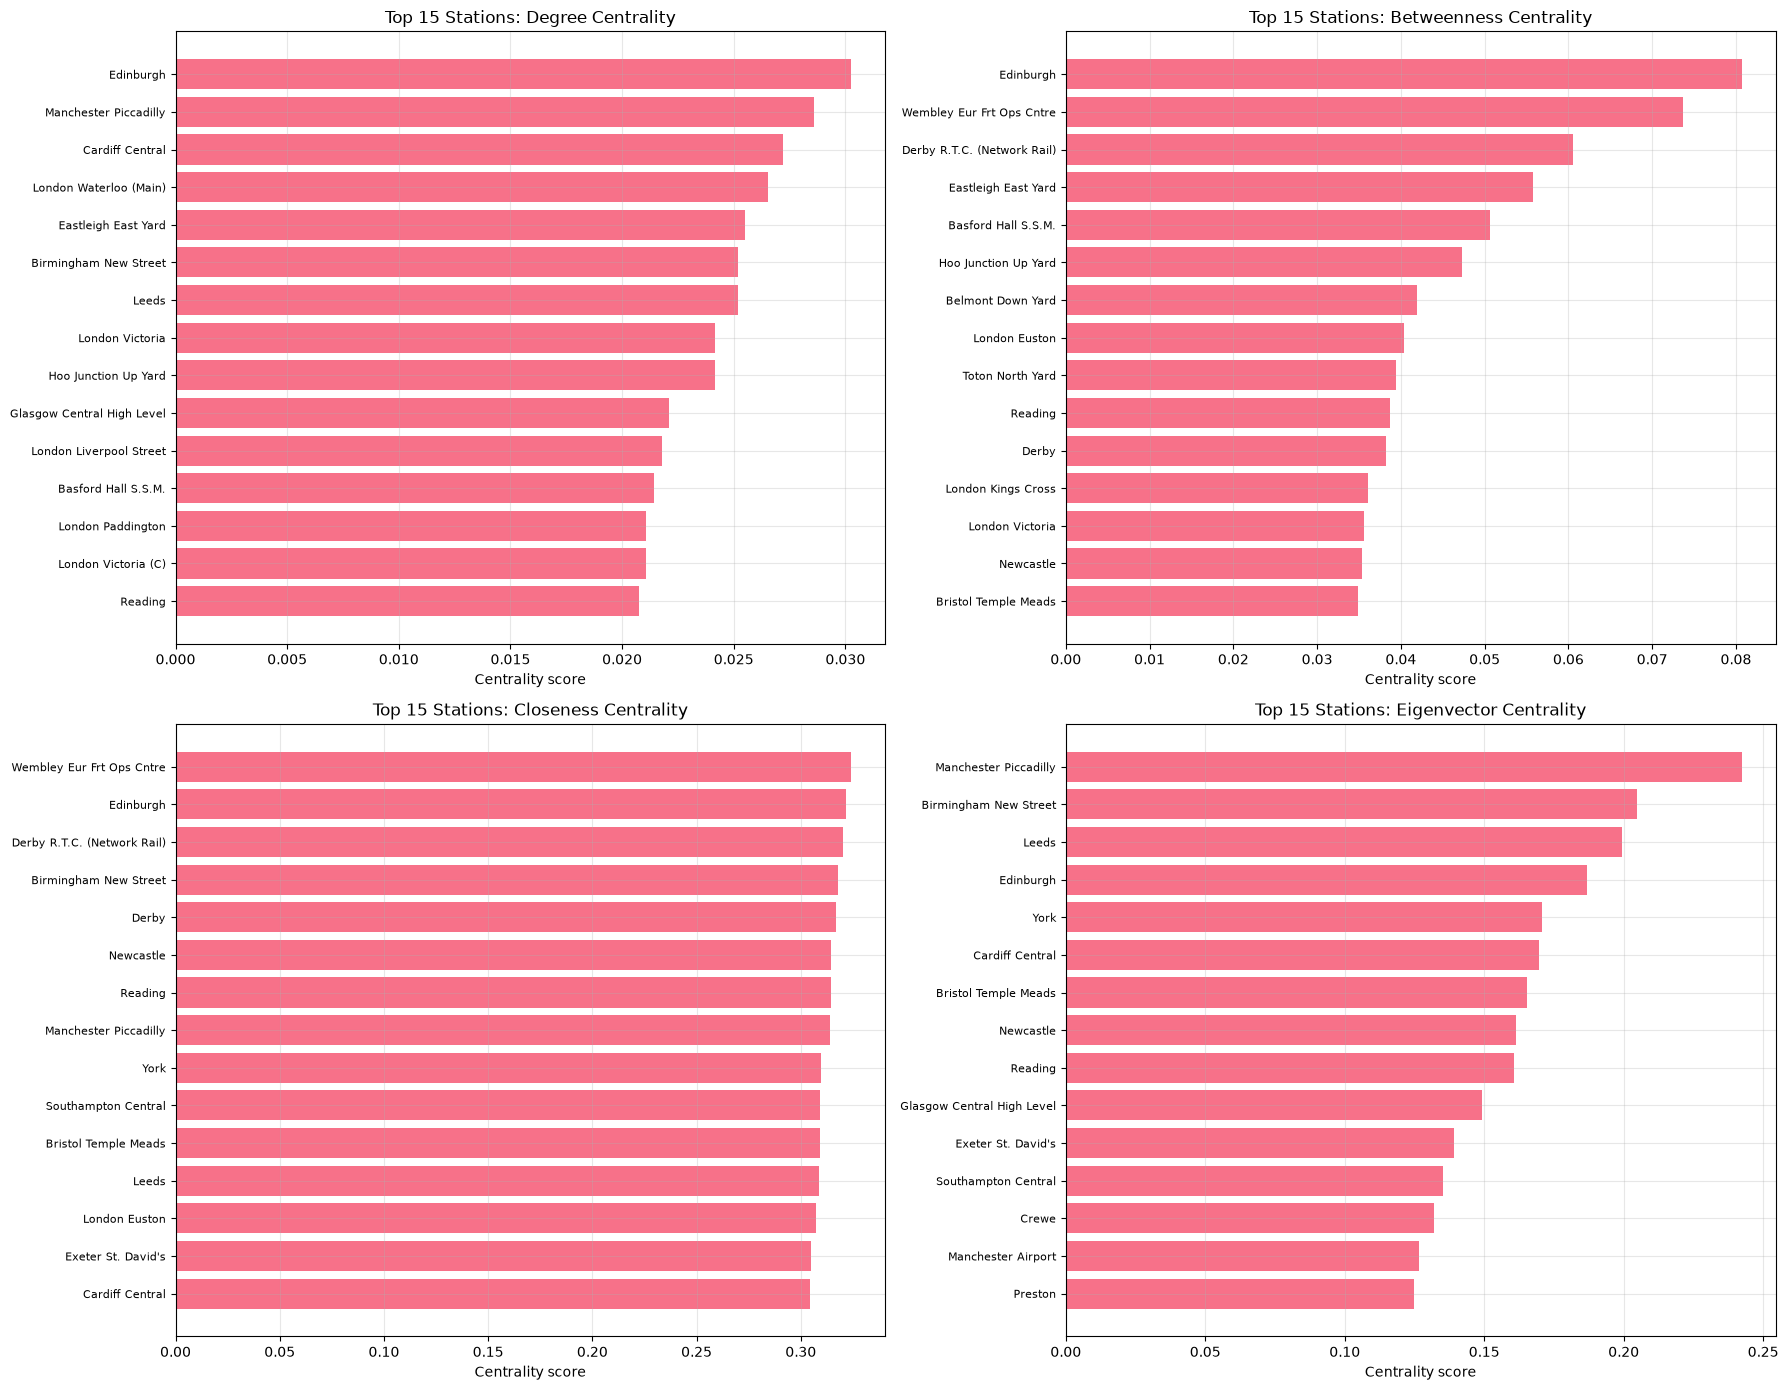

In [16]:
centrality_names = ["degree", "betweenness", "closeness", "eigenvector"]
centrality_titles = [
    "Degree Centrality",
    "Betweenness Centrality",
    "Closeness Centrality",
    "Eigenvector Centrality"
]

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for ax, name, title in zip(axes, centrality_names, centrality_titles):
    top_stations = sorted(
        centralities[name].items(),
        key=lambda item: item[1],
        reverse=True
    )[:15]

    stations = [item[0] for item in top_stations]
    scores = [item[1] for item in top_stations]

    ax.barh(range(len(stations)), scores)
    ax.set_yticks(range(len(stations)))
    ax.set_yticklabels(stations, fontsize=8)
    ax.set_xlabel("Centrality score")
    ax.set_title(f"Top 15 Stations: {title}")
    ax.grid(True, alpha=0.3)
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig("uk_rail_centrality_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Assignment 2